In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *

import pandas as pd
# import seaborn as sns

In [ ]:
from pyCRLD.Environments.SocialDilemma import SocialDilemma
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import matplotlib.pyplot as plt

In [ ]:
import matplotlib as mpl
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s

In [ ]:
def reward_traj(mae,  # CRLD multi-agent environment object
                X:tuple,  # strategy
                i,  # agent
                NrRandom:int=3,  # how many random (in the other dimensions) stratgies for averaging 
                traj_len:int=500,  # trajectory length
                ): 
    
    # x axis
    r_traj = np.zeros((traj_len))
    traj, fpreached = mae.trajectory(X, traj_len) # compute trajectory
    for t in range(traj_len):
        r_traj[t] = mae.Ri(traj[t,...])[i]
    return r_traj
    

def compare_levels(env,
                   level_list,  # level list
                   method,  # used method
                   gamma,
                   beta,
                   Rmin,
                   Rmax,
                   x:tuple,  # which phase space axes to plot along x axes
                   res,  # specify range & resolution
                   nrb:int=29,
                   discsig:float=0.05,
                   lr:float=0.1,
                   NrRandom:int=4,  # how many random (in the other dimensions) stratgies for averaging 
                   traj_len:int=500,  # trajectory length
                   cmap='viridis',  # Colormap
                   acts=None,  # Action descriptions
                   conds=None,  # Conditions descriptions 
                   axes=None,  # Axes to plot into
                   verbose=False,  # shall I talk to you while working?
                   ):  
   

    # Fig and Axes
    states = 1
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(3 * 3.8, 3.8))
    cmap = mpl.cm.get_cmap(cmap)
    ext = np.linspace(0, 1, len(level_list))
    colors = cmap(tuple(ext))
    
    # x axis
    xs = res
    zero = np.zeros((len(xs)))

    # The Plots
    for j, l in enumerate(level_list):
        print(l)
        if method=='weights':
            mae = qbaseSARSA(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                             learning_rates=lr, discount_factors=gamma, 
                             choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                             method=method, wU=l, use_prefactor=True)
                             
        elif method=='expectile':
            mae = qbaseSARSA(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                             learning_rates=lr, discount_factors=gamma, 
                             choice_intensities=beta, Rmin=Rmin, Rmax=Rmax,
                             method=method, tau=l, use_prefactor=True)
            
        xinds = (x[0][0], x[1][0], x[2][0])  # fix this later
            
        # obtain the data to plot
        RPEs, dXs = _data_to_plot(mae, res, xinds, traj_len, NrRandom, 
                                  phasespace_items=_strategies, verbose=verbose)
        ax1.plot(xs, dXs[0, :], color=colors[j], label=r'$\tau=$'+str(l))
        ax1.plot(xs, zero, color="grey", ls='dashed')
        
        # obtain reward traj
        X0 = np.ones((mae.N, mae.Z, mae.M)) * 0.5
        r_traj = reward_traj(mae, X0, 0, traj_len=traj_len)
        ax2.plot(np.arange(0, traj_len), r_traj, color=colors[j], label=r'$\tau=$'+str(l))
        
    ax1.set_ylabel(r"$dX$")
    ax1.set_xlabel(r'$X^{0}_{00}$')
    ax2.set_xlabel('time step')
    ax2.set_title('mean reward obtained by agent 0 over time')
    ax1.set_title('phase plot')
    ax2.legend(bbox_to_anchor=(1.01, 1.01))
    
    # return fig

## Two-armed bandit

In [ ]:
# poor environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

In [ ]:
weights = np.array([.1, .4, .7, 1., 4., 7., 10.])
expectiles = [0.10, 0.30, 0.50, 0.70, 0.90]

x = ([0], [0], [0]) 
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_33084/2771973148.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


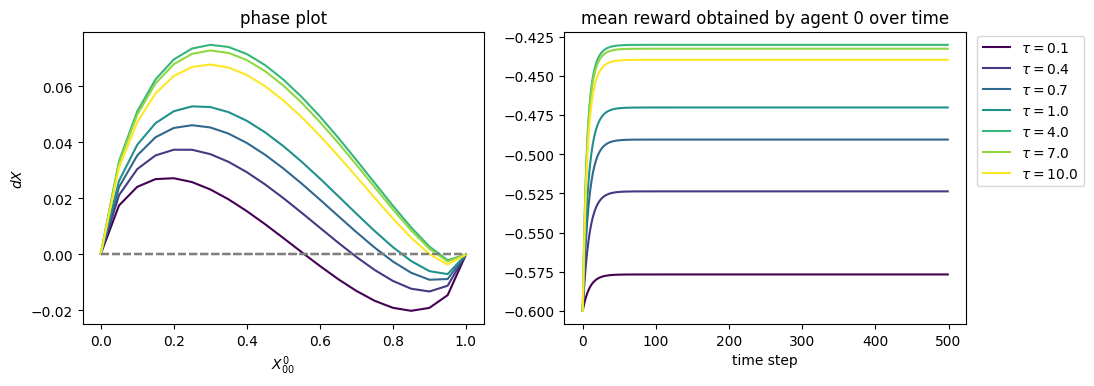

In [ ]:
compare_levels(env, weights, method='weights', gamma=0, beta=4, Rmin=-1, Rmax=1, x=x, res=res)

/tmp/ipykernel_13374/2264874812.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.3
0.5
0.7
0.9


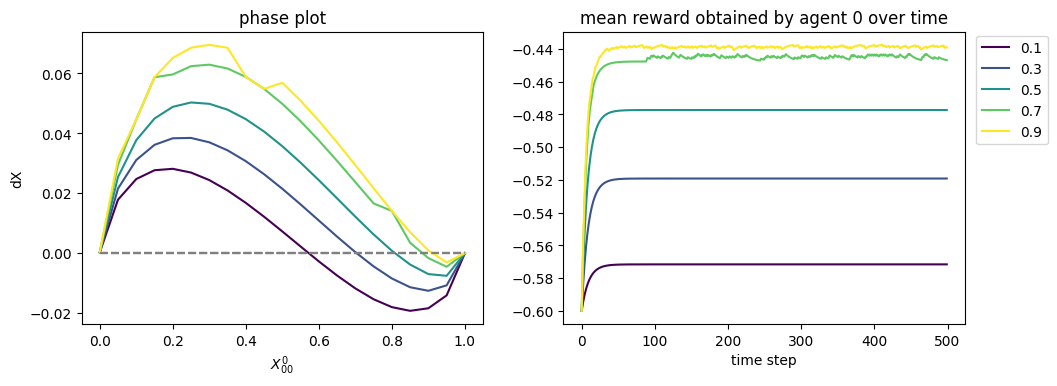

In [ ]:
compare_levels(env, expectiles, method='expectile', gamma=0, beta=4, Rmin=-1, Rmax=1, x=x, res=res, NrRandom=16)

## Risk-Reward Dilemma

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

In [ ]:
x = ([0], [0], [0])  # probability of being cautious in the prosperous state
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_13374/2264874812.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


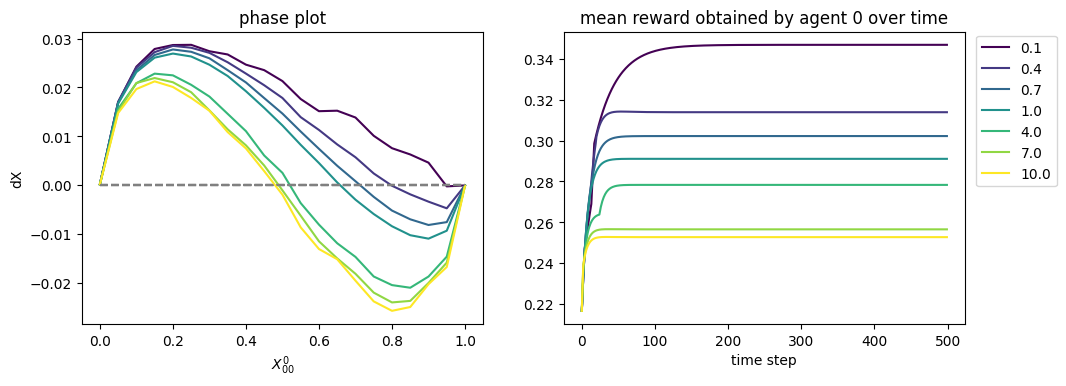

In [ ]:
compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=0, Rmax=1, x=x, res=res, NrRandom=100)

/tmp/ipykernel_10006/2771973148.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1


No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


0.3
0.5
0.7
0.9


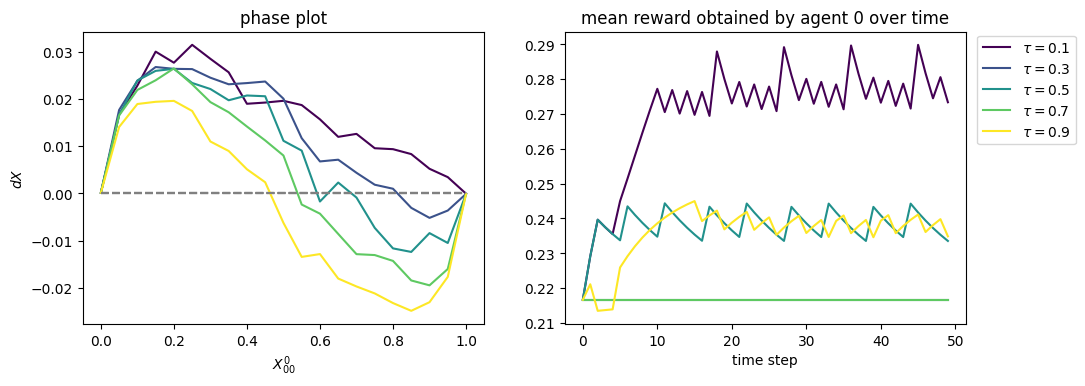

In [ ]:
compare_levels(env, expectiles, method='expectile', gamma=0.9, beta=50, Rmin=0, Rmax=1, x=x, res=res, NrRandom=100, traj_len=50)

## Stag-Hunt Game

In [ ]:
env = SocialDilemma(R=3, S=-2, T=1, P=0)

In [ ]:
x = ([0], [0], [0])  # probability of cooperating for agent 1
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_33084/2771973148.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


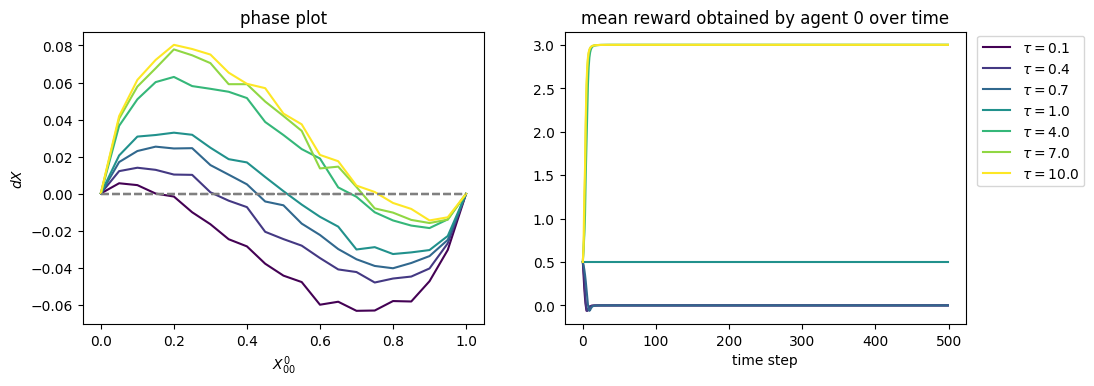

In [ ]:
compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, NrRandom=100)

/tmp/ipykernel_10006/2771973148.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.99
1.0
1.01


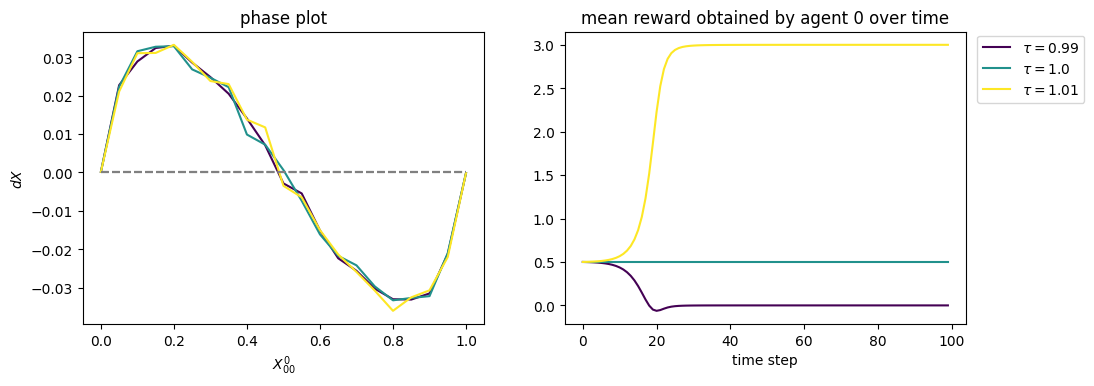

In [ ]:
weights = np.array([0.99, 1., 1.01])

compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, NrRandom=100, traj_len=100)

Text(0, 0.5, 'prob of cooperating')

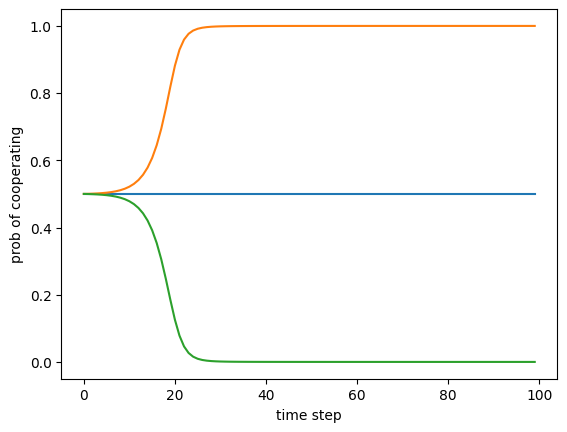

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                 learning_rates=0.1, discount_factors=0.9, 
                 choice_intensities=50, Rmin=-2, Rmax=3,
                 method='weights', wU=1., use_prefactor=True)
mae1 = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                  learning_rates=0.1, discount_factors=0.9, 
                  choice_intensities=50, Rmin=-2, Rmax=3,
                  method='weights', wU=1.01, use_prefactor=True)
mae2 = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.05, 
                  learning_rates=0.1, discount_factors=0.9, 
                  choice_intensities=50, Rmin=-2, Rmax=3,
                  method='weights', wU=0.99, use_prefactor=True)

X = jnp.ones((2, 1, 2)) * 0.5
X1 = jnp.ones((2, 1, 2)) * 0.5
X2 = jnp.ones((2, 1, 2)) * 0.5
traj_len=100

traj, fpreached = mae.trajectory(X, traj_len)
traj1, fpreached = mae1.trajectory(X1, traj_len)
traj2, fpreached = mae2.trajectory(X2, traj_len)

plt.figure()
plt.plot(np.arange(0, traj_len), traj[:, 0, 0, 0])
plt.plot(np.arange(0, traj_len), traj1[:, 0, 0, 0])
plt.plot(np.arange(0, traj_len), traj2[:, 0, 0, 0])
plt.xlabel("time step")
plt.ylabel("prob of cooperating")

/tmp/ipykernel_13374/2264874812.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.3
0.5
0.7
0.9


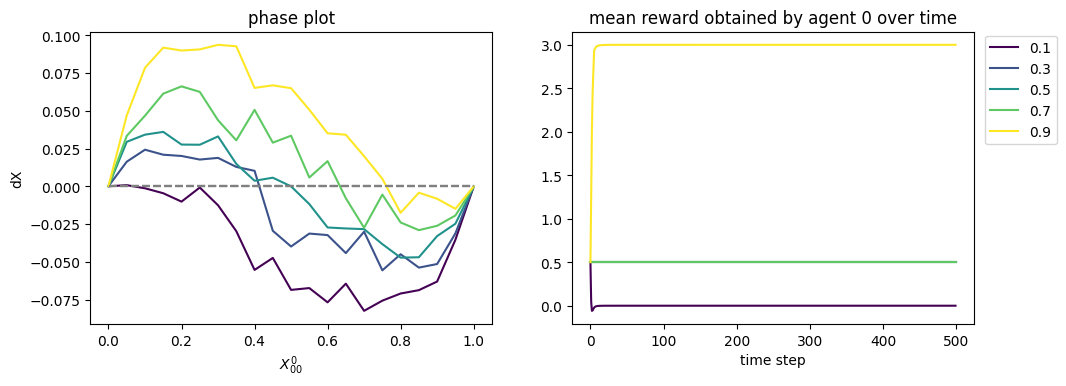

In [ ]:
compare_levels(env, expectiles, method='expectile', gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, NrRandom=100)

## Prisoner's Dilemma

In [ ]:
env = SocialDilemma(R=1, S=-2, T=3, P=0)

In [ ]:
x = ([0], [0], [0])  # probability of cooperating for agent 1
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_13374/2264874812.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


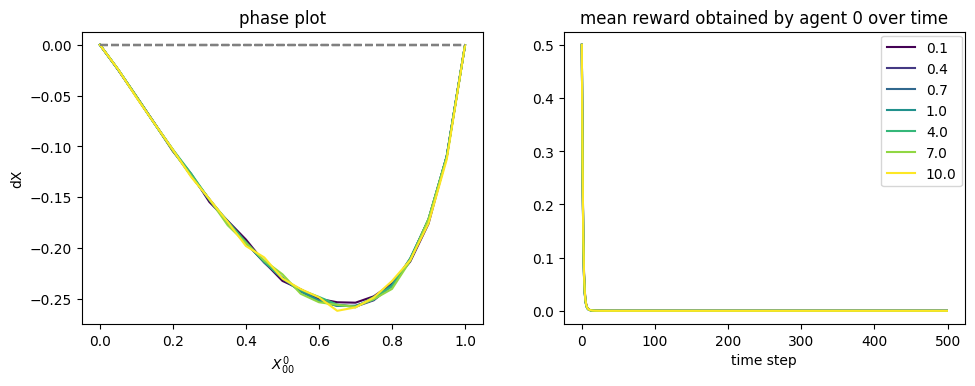

In [ ]:
compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, NrRandom=100)

/tmp/ipykernel_13374/2264874812.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.1
0.3
0.5
0.7
0.9


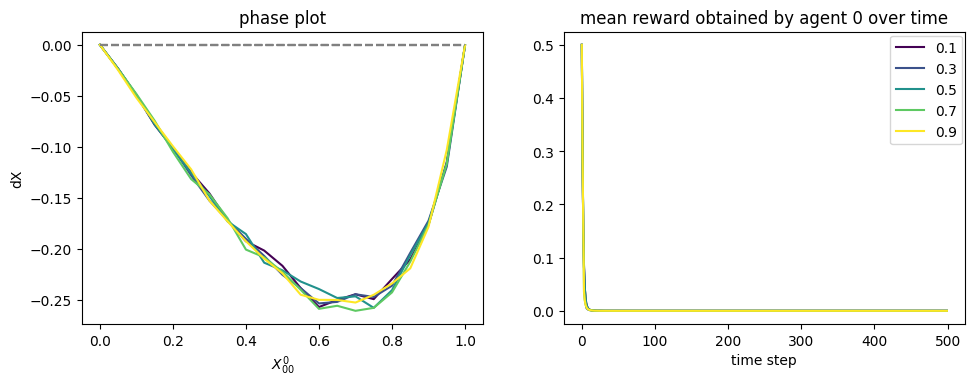

In [ ]:
compare_levels(env, expectiles, method='expectile', gamma=0.9, beta=50, Rmin=-2, Rmax=3, x=x, res=res, NrRandom=100)

## Risk-Reward Dilemma with asymmetric degraded state

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0, asym=True, rdr=0.01)

/tmp/ipykernel_17868/2264874812.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)
No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


0.1
0.4
0.7
1.0
4.0
7.0
10.0


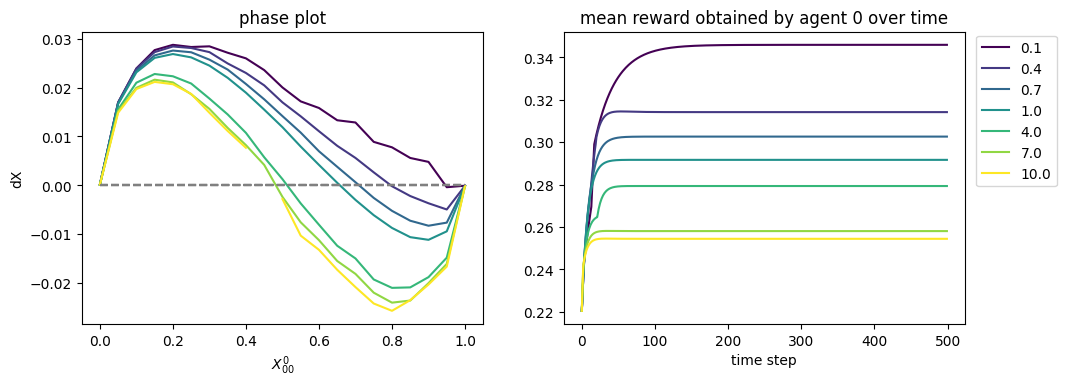

In [ ]:
compare_levels(env, weights, method='weights', gamma=0.9, beta=50, Rmin=0, Rmax=1, x=x, res=res, NrRandom=100)